# Airline Passenger Satisfaction: Week 2 Feature Engineering


## 1. Setup, loading and the split

In [1]:
import io
import inspect
import sys
from functools import partial
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, VarianceThreshold
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, OrdinalEncoder,
                                   PowerTransformer, RobustScaler)

# works both from the repo root and from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from airline_fe.config import (AGE, CLASS_ORDER, DELAY_PAIR, ID_COL, LIKERT, NOMINAL,
                               ORDINAL, RANDOM_STATE, SKEWED, TARGET)
from airline_fe.evaluation import CappedRFECV, mi_subsampled
from airline_fe.transformers import DelayFeatureEngineer, LikertZeroFlagger
from airline_fe.transformers_upgraded import LikertLevelEncoder

candidates = [ROOT / "data" / "raw" / "airline_passenger_satisfaction.csv",
              ROOT / "airline_passenger_satisfaction.csv"]
DATA_PATH = next(p for p in candidates if p.exists())
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)

X = df.drop(columns=[ID_COL, TARGET])
y = df[TARGET].map({"Satisfied": 1, "Neutral or Dissatisfied": 0})
assert y.notna().all()

# split before looking at anything else
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("train:", X_train.shape, " test:", X_test.shape)
print("share satisfied (train):", round(y_train.mean(), 4))

(129880, 24)
train: (103904, 22)  test: (25976, 22)
share satisfied (train): 0.4345


A quick sanity check that the raw columns look the way we expect (this is also the check we'll reuse in the Week 4 app before calling `predict`):

In [3]:
expected_cols = ["Gender", "Age", "Customer Type", "Type of Travel", "Class",
                 "Flight Distance", "Departure Delay", "Arrival Delay"] + LIKERT
assert list(X_train.columns) == expected_cols
assert set(X_train["Class"]) == set(CLASS_ORDER[0])
assert X_train[LIKERT].isin(range(6)).all().all()
assert X_train.columns[X_train.isna().any()].tolist() == ["Arrival Delay"]

Training-set profile of the numeric columns. This is where the skew / zero / missing numbers in the summary table come from.

In [4]:
num_cols = ["Age", "Flight Distance", "Departure Delay", "Arrival Delay"] + LIKERT
profile = pd.DataFrame({
    "min": X_train[num_cols].min(),
    "median": X_train[num_cols].median(),
    "max": X_train[num_cols].max(),
    "skew": X_train[num_cols].skew(),
    "zeros_%": X_train[num_cols].eq(0).mean() * 100,
    "missing": X_train[num_cols].isna().sum(),
})
profile.round(3)

,min,median,max,skew,zeros_%,missing
Age,7.0,40.0,85.0,-0.000,0.000,0
Flight Distance,31.0,844.0,4983.0,1.109,0.000,0
Departure Delay,0.0,0.0,1592.0,6.832,56.478,0
Arrival Delay,0.0,0.0,1584.0,6.700,56.044,321
Departure and Arrival Time Convenience,0.0,3.0,5.0,-0.335,5.175,0
Ease of Online Booking,0.0,3.0,5.0,-0.023,4.367,0
Check-in Service,1.0,3.0,5.0,-0.365,0.000,0
Online Boarding,0.0,3.0,5.0,-0.458,2.388,0
Gate Location,1.0,3.0,5.0,-0.062,0.000,0
On-board Service,0.0,4.0,5.0,-0.422,0.003,0


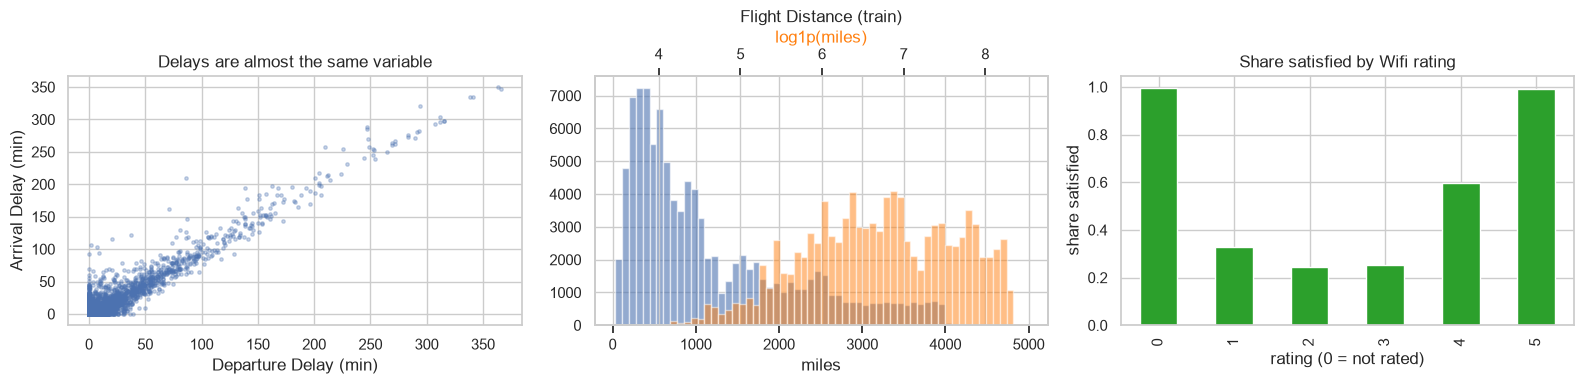

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sample = X_train.sample(5000, random_state=RANDOM_STATE)
axes[0].scatter(sample["Departure Delay"], sample["Arrival Delay"], s=6, alpha=0.3)
axes[0].set(xlabel="Departure Delay (min)", ylabel="Arrival Delay (min)",
            title="Delays are almost the same variable")

axes[1].hist(X_train["Flight Distance"], bins=60, alpha=0.6, label="raw")
axes[1].set(title="Flight Distance (train)", xlabel="miles")
ax2 = axes[1].twiny()
ax2.hist(np.log1p(X_train["Flight Distance"]), bins=60, alpha=0.5, color="tab:orange", label="log1p")
ax2.set_xlabel("log1p(miles)", color="tab:orange")

sat_by_rating = (pd.DataFrame({"rating": X_train["In-flight Wifi Service"], "y": y_train})
                 .groupby("rating")["y"].mean())
sat_by_rating.plot.bar(ax=axes[2], color="tab:green")
axes[2].set(title="Share satisfied by Wifi rating", ylabel="share satisfied", xlabel="rating (0 = not rated)")
plt.tight_layout()
plt.show()

Three things from these plots drove our engineering steps. The two delays sit on a diagonal. Flight Distance has a long right tail that `log1p` pulls in. And a Wifi rating of 0 behaves completely differently from a rating of 1: those passengers are almost all satisfied. So treating 0 as "the lowest score" would be wrong.

## 2. Custom transformers

Both custom classes live in `src/airline_fe/transformers.py`, so a saved pipeline can be loaded again with `joblib` in Week 4. Source printed here so it's visible in the PDF.

In [6]:
print(inspect.getsource(DelayFeatureEngineer))

class DelayFeatureEngineer(BaseEstimator, TransformerMixin):
    """Create net delay recovery while learning imputation on fit data only.

    Input order is departure delay, then arrival delay. For missing arrival
    values, ``net_median`` imputes the net delay directly; ``arrival_median``
    imputes arrival delay before subtraction.
    """

    def __init__(self, impute_strategy="net_median"):
        self.impute_strategy = impute_strategy

    def fit(self, X, y=None):
        if self.impute_strategy not in {"net_median", "arrival_median"}:
            raise ValueError(
                "impute_strategy must be 'net_median' or 'arrival_median'."
            )
        values = _as_2d_array(X, 2, self.__class__.__name__)
        departure, arrival = values[:, 0], values[:, 1]
        valid_net = np.isfinite(departure) & np.isfinite(arrival)
        valid_departure = np.isfinite(departure)
        valid_arrival = np.isfinite(arrival)
        if not valid_net.any() or not valid_depart

In [7]:
print(inspect.getsource(LikertZeroFlagger))

class LikertZeroFlagger(BaseEstimator, TransformerMixin):
    """Create float indicators for zero-valued (not applicable) ratings."""

    def __init__(self, na_value=0):
        self.na_value = na_value

    def fit(self, X, y=None):
        values = np.asarray(X, dtype=float) if not isinstance(X, pd.DataFrame) else X.to_numpy(dtype=float)
        if values.ndim != 2:
            raise ValueError("LikertZeroFlagger expects a 2D input.")
        self.n_features_in_ = values.shape[1]
        if isinstance(X, pd.DataFrame):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        else:
            self.feature_names_in_ = np.asarray(
                [f"x{i}" for i in range(self.n_features_in_)], dtype=object
            )
        if self.n_features_in_ == len(LIKERT) and isinstance(X, pd.DataFrame):
            if list(self.feature_names_in_) != LIKERT:
                raise ValueError("Likert columns do not match the configured schema.")
        return self

    

A small hand-made check of `DelayFeatureEngineer`: a normal row, a missing arrival, a missing departure, both missing, and a flight that recovered time in the air.

In [8]:
toy = pd.DataFrame({"Departure Delay": [30, 60, np.nan, np.nan, 40],
                    "Arrival Delay":   [10, np.nan, 5, np.nan, 0]})
toy_pipe = Pipeline([("net", DelayFeatureEngineer())]).fit(toy)
dfe = toy_pipe.named_steps["net"]
print("learned medians: net =", dfe.median_net_, " departure =", dfe.median_departure_)
print(pd.DataFrame({"input_dep": toy.iloc[:, 0], "input_arr": toy.iloc[:, 1],
                    "net_delay_recovery": toy_pipe.transform(toy).ravel()}))

learned medians: net = 30.0  departure = 40.0
   input_dep  input_arr  net_delay_recovery
0       30.0       10.0                20.0
1       60.0        NaN                30.0
2        NaN        5.0                35.0
3        NaN        NaN                30.0
4       40.0        0.0                40.0


## 3. Variance analysis

First the raw numeric columns, then the 14 candidate zero-flags. A binary flag with prevalence *p* has variance *p(1 − p)*, so the 1% prevalence cut-off we want is `VarianceThreshold(0.0099)`. Below 1% means fewer than ~1,000 positive rows in train, and the LR coefficient for such a flag would mostly fit noise.

In [9]:
X_train[num_cols].var().to_frame("variance").round(3).T

,Age,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling
variance,229.482,996089.546,1462.508,1490.799,2.334,1.965,1.605,1.823,1.633,1.655,1.74,1.733,1.727,1.765,1.384,1.765,1.778,1.394


In [10]:
for col in NOMINAL + ORDINAL:
    print(col, (X_train[col].value_counts(normalize=True) * 100).round(1).to_dict())

Gender {'Female': 50.7, 'Male': 49.3}
Customer Type {'Returning': 81.6, 'First-time': 18.4}
Type of Travel {'Business': 69.0, 'Personal': 31.0}
Class {'Business': 47.8, 'Economy': 44.9, 'Economy Plus': 7.3}


In [11]:
VAR_THRESHOLD = 0.0099

p = X_train[LIKERT].eq(0).mean()
flags = pd.DataFrame({
    "zero_rows": X_train[LIKERT].eq(0).sum(),
    "prevalence_%": (p * 100).round(3),
    "flag_variance": (p * (1 - p)).round(5),
})

def flag_decision(row):
    if row.flag_variance >= VAR_THRESHOLD:
        return "keep", "enough 'not used' passengers to learn a stable effect"
    if row.zero_rows == 0:
        return "drop", "constant in train (no zeros), carries no information"
    if row.zero_rows < 100:
        return "drop", f"only {row.zero_rows} rows, coefficient would be noise"
    return "drop", "below 1% prevalence"

flags[["decision", "reason"]] = flags.apply(flag_decision, axis=1, result_type="expand")
flags.sort_values("flag_variance", ascending=False)

,zero_rows,prevalence_%,flag_variance,decision,reason
Departure and Arrival Time Convenience,5377,5.175,0.04907,keep,enough 'not used' passengers to learn a stable...
Ease of Online Booking,4538,4.367,0.04177,keep,enough 'not used' passengers to learn a stable...
In-flight Wifi Service,3128,3.010,0.02920,keep,enough 'not used' passengers to learn a stable...
Online Boarding,2481,2.388,0.02331,keep,enough 'not used' passengers to learn a stable...
Leg Room Service,474,0.456,0.00454,drop,below 1% prevalence
Food and Drink,104,0.100,0.00100,drop,below 1% prevalence
In-flight Entertainment,14,0.013,0.00013,drop,"only 14.0 rows, coefficient would be noise"
Cleanliness,11,0.011,0.00011,drop,"only 11.0 rows, coefficient would be noise"
On-board Service,3,0.003,0.00003,drop,"only 3.0 rows, coefficient would be noise"
In-flight Service,3,0.003,0.00003,drop,"only 3.0 rows, coefficient would be noise"


Ten of the 14 flags don't make it:

- **constant in train**: Check-in Service, Gate Location, Seat Comfort, Baggage Handling never have a 0, so their flag is all zeros;
- **a handful of rows**: On-board Service, In-flight Service, Cleanliness and Entertainment have between 3 and 13 zeros out of 103,904, far too few for a coefficient that means anything;
- **below 1%**: Food and Drink (0.10%) and Leg Room Service (0.46%).

The four we keep are Time Convenience, Ease of Online Booking, Online Boarding and Wifi. Those are the optional or digital services, so it makes sense that 2–5% of passengers simply didn't use them. None of the raw columns is close to constant: the smallest categorical level is Economy Plus at 7.3%, and every rating has a variance above 1. So the flag filter is the only variance-based removal. We test it as its own step (S4) instead of just assuming it's harmless.

## 4. Correlation analysis

Pearson on the 18 numeric columns (the 4 continuous ones + 14 ratings), and Spearman for the rating block on its own, since the ratings are ordinal. Both are computed on `X_train`.

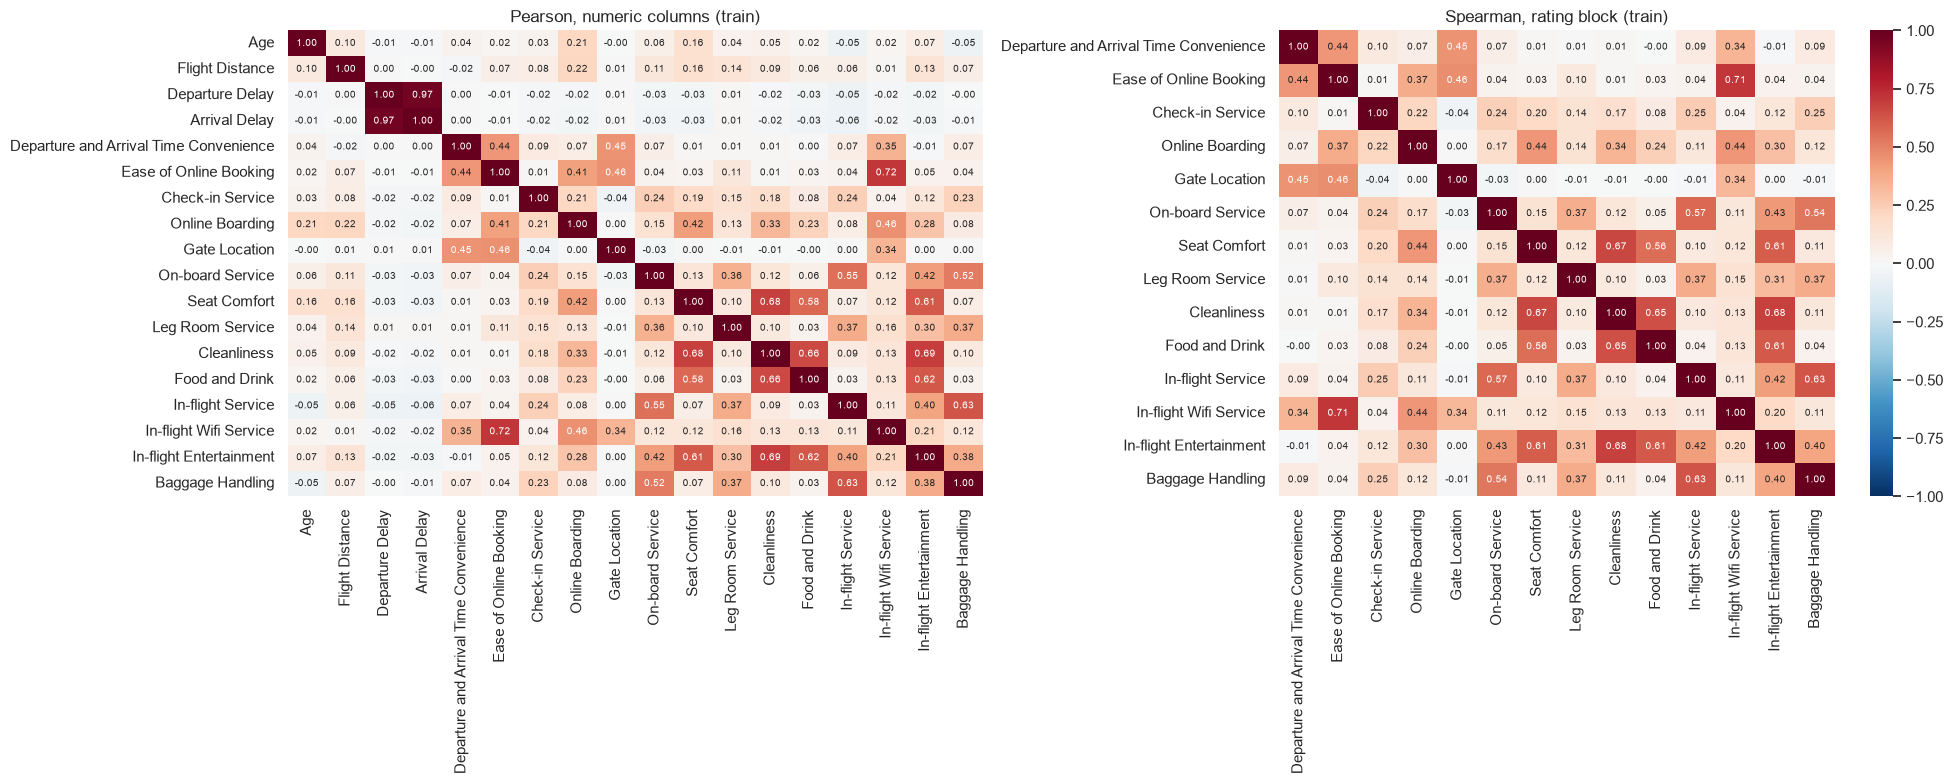

In [12]:
pearson = X_train[num_cols].corr()
spearman = X_train[LIKERT].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(pearson, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=axes[0], cbar=False)
axes[0].set_title("Pearson, numeric columns (train)")
sns.heatmap(spearman, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Spearman, rating block (train)")
plt.tight_layout()
plt.show()

In [13]:
def corr_pairs(corr, low, high=1.0):
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
    out = upper[(upper.abs() > low) & (upper.abs() <= high)]
    return out.sort_values(key=abs, ascending=False).rename("r").to_frame()

print("|r| > 0.90:")
display(corr_pairs(pearson, 0.90).round(3))
print("0.60 < |r| <= 0.90:")
display(corr_pairs(pearson, 0.60, 0.90).round(3))

|r| > 0.90:


,,r
Departure Delay,Arrival Delay,0.966


0.60 < |r| <= 0.90:


,,r
Ease of Online Booking,In-flight Wifi Service,0.716
Cleanliness,In-flight Entertainment,0.693
Seat Comfort,Cleanliness,0.680
Cleanliness,Food and Drink,0.657
In-flight Service,Baggage Handling,0.630
Food and Drink,In-flight Entertainment,0.624
Seat Comfort,In-flight Entertainment,0.613


Only one pair is above 0.90, and it's the one we expected.

| Pair | r (train) | Decision | Reasoning |
|---|---|---|---|
| Departure Delay ↔ Arrival Delay | 0.966 | **combine** into `Net Delay Recovery`, drop `Arrival Delay` | Dropping one would lose the "made up time in the air" information. Keeping both gives LR two near-identical columns with unstable coefficients. The difference keeps the extra information without the redundancy. |
| Ease of Online Booking ↔ In-flight Wifi | 0.71 | **keep both** | Below 0.90, and they're different touchpoints (booking vs on-board). We let selection decide. |
| Cleanliness / Seat Comfort / Entertainment / Food (0.61–0.69) | 0.61–0.69 | **keep both** | Below threshold. These are the natural candidates for RFECV to drop, so we'll watch them in section 6. |

## 5. Feature engineering, step by step

The pipeline builder below has switches for each engineering idea, so each step adds exactly one change on top of the previous one:

- **S0** baseline: raw features, median imputation, RobustScaler, encoders
- **S1** replace raw Arrival Delay with Net Delay Recovery (plus **S1b**: same thing, but imputing Arrival with its own median)
- **S2** log1p on Flight Distance and Departure Delay
- **S3** add all 14 zero-flags
- **S4** keep only the flags that pass the variance filter

All steps use the same 5 folds, so we can compare them *fold by fold*. A change counts as real only if the mean paired difference is bigger than its own fold-to-fold standard deviation. Otherwise we call it "maintained".

In [14]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1"}


def numeric(log=False):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if log:
        steps.append(("log1p", FunctionTransformer(np.log1p, inverse_func=np.expm1,
                                                   feature_names_out="one-to-one")))
    steps.append(("scale", RobustScaler()))
    return Pipeline(steps)


def build_preprocessor(delay="net", log_skewed=True, flags="nzv",
                       impute_strategy="net_median", likert="numeric"):
    branches = [
        ("nominal", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), NOMINAL),
        ("class", OrdinalEncoder(categories=CLASS_ORDER, handle_unknown="use_encoded_value",
                                 unknown_value=-1), ORDINAL),
        ("age", numeric(), AGE),
        ("skewed", numeric(log=log_skewed), SKEWED),
    ]
    if delay == "raw":
        branches.append(("arrival", numeric(), ["Arrival Delay"]))
    else:
        branches.append(("net_delay", Pipeline([
            ("net", DelayFeatureEngineer(impute_strategy=impute_strategy)),
            ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
            ("scale", RobustScaler()),
        ]), DELAY_PAIR))

    if likert == "levels":  # only used for the side experiment after S4
        branches.append(("likert", LikertLevelEncoder(), LIKERT))
    else:
        branches.append(("likert", numeric(), LIKERT))

    if flags != "none":
        # "all" = no filter at all; VarianceThreshold(0) would still drop the constant ones
        nzv = VarianceThreshold(VAR_THRESHOLD) if flags == "nzv" else "passthrough"
        branches.append(("likert_flags", Pipeline([("flag", LikertZeroFlagger()), ("nzv", nzv)]), LIKERT))

    return ColumnTransformer(branches, remainder="drop",
                             verbose_feature_names_out=False).set_output(transform="pandas")


def make_pipe(selector="passthrough", **pre_kw):
    return Pipeline([
        ("preprocess", build_preprocessor(**pre_kw)),
        ("select", selector),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])


STEPS = {
    "S0": dict(delay="raw", log_skewed=False, flags="none"),
    "S1": dict(delay="net", log_skewed=False, flags="none"),
    "S1b": dict(delay="net", log_skewed=False, flags="none", impute_strategy="arrival_median"),
    "S2": dict(delay="net", log_skewed=True, flags="none"),
    "S3": dict(delay="net", log_skewed=True, flags="all"),
    "S4": dict(delay="net", log_skewed=True, flags="nzv"),
}

In [15]:
cv_log = []
fold_auc = {}


def log_step(step, description, pipe=None, ref=None, result=None):
    # runs 5-fold CV (unless a result is passed in), adds a row to the log and shows it
    if result is None:
        result = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1,
                                return_train_score=True, return_estimator=True)
    fold_auc[step] = result["test_roc_auc"]
    n_features = len(result["estimator"][0][:-1].get_feature_names_out())

    row = {"step": step, "description": description, "n_features": n_features}
    for m in SCORING:
        row[f"{m}_mean"] = result[f"test_{m}"].mean()
        row[f"{m}_std"] = result[f"test_{m}"].std(ddof=1)
    row["train_roc_auc"] = result["train_roc_auc"].mean()

    ref = ref or (cv_log[-1]["step"] if cv_log else None)
    if ref is not None:
        diff = fold_auc[step] - fold_auc[ref]
        row.update(ref=ref, delta_roc_auc=diff.mean(), paired_std=diff.std(ddof=1))
        if diff.mean() > diff.std(ddof=1):
            row["verdict"] = "improved"
        elif diff.mean() < -diff.std(ddof=1):
            row["verdict"] = "worsened"
        else:
            row["verdict"] = "maintained"
    row["fit_time_s"] = result["fit_time"].mean()
    cv_log.append(row)

    show = pd.DataFrame(cv_log).set_index("step").drop(columns="description")
    display(show.round(5))
    return result

### S0: baseline

In [16]:
res_s0 = log_step("S0", "raw features, impute + RobustScaler + encoders", make_pipe(**STEPS["S0"]))

,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc,fit_time_s
step,,,,,,,,,
S0,22,0.92557,0.00187,0.92997,0.00177,0.8513,0.00315,0.92564,0.57805


The baseline is already quite strong for plain LR: ROC-AUC **0.9256 ± 0.0019**, PR-AUC 0.9300, F1 0.851. Train and CV ROC-AUC are identical to three decimals (0.9256 vs 0.9256), so there's no overfitting at all. If anything the model is too simple. That's a hint that better *features* should help more than more regularisation, and every later step is compared against these numbers.

### S1: Net Delay Recovery instead of Arrival Delay

In [17]:
res_s1 = log_step("S1", "Departure - Arrival -> Net Delay Recovery, drop Arrival", make_pipe(**STEPS["S1"]))

,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc,fit_time_s,ref,delta_roc_auc,paired_std,verdict
step,,,,,,,,,,,,,
S0,22,0.92557,0.00187,0.92997,0.00177,0.85130,0.00315,0.92564,0.57805,NaN,NaN,NaN,NaN
S1,22,0.92550,0.00189,0.92991,0.00177,0.85128,0.00304,0.92557,0.55364,S0,-0.00007,0.00004,worsened


The score isn't the main reason for this step; coefficient stability is. Here is how much the delay coefficients move between folds, before and after:

In [18]:
def coef_table(result, names):
    coefs = pd.DataFrame([est[-1].coef_[0] for est in result["estimator"]],
                         columns=result["estimator"][0][:-1].get_feature_names_out())
    return coefs[names].agg(["mean", "std"]).T

print("S0")
display(coef_table(res_s0, ["Departure Delay", "Arrival Delay"]).round(4))
print("S1")
display(coef_table(res_s1, ["Departure Delay", "Net Delay Recovery"]).round(4))

S0


,mean,std
Departure Delay,0.0444,0.0067
Arrival Delay,-0.1108,0.0068


S1


,mean,std
Departure Delay,-0.0585,0.0022
Net Delay Recovery,0.0172,0.0009


On score, S1 changes nothing: 0.92550 vs 0.92557. The −0.00007 difference is consistent across folds, so our rule labels it "worsened", but it's a hundredth of a percentage point, and we don't read anything into it.

The real reason for this step is in the coefficients. In S0, Departure Delay gets a *positive* coefficient (+0.044) and Arrival Delay a negative one (−0.111). That's two collinear columns cancelling each other, not evidence that departing late makes people happier. After S1, Departure Delay is negative as you'd expect (−0.059), Net Delay Recovery is slightly positive (making up time in the air helps a little), and the fold-to-fold std of the delay coefficient drops from 0.0067 to 0.0022. We want to interpret coefficients and SHAP values later, so we keep S1 even though it doesn't move the score.

### S1b: does the imputation strategy for Arrival Delay matter?

In [19]:
res_s1b = log_step("S1b", "S1 but impute Arrival with its own median", make_pipe(**STEPS["S1b"]), ref="S1")

,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc,fit_time_s,ref,delta_roc_auc,paired_std,verdict
step,,,,,,,,,,,,,
S0,22,0.92557,0.00187,0.92997,0.00177,0.85130,0.00315,0.92564,0.57805,NaN,NaN,NaN,NaN
S1,22,0.92550,0.00189,0.92991,0.00177,0.85128,0.00304,0.92557,0.55364,S0,-0.00007,0.00004,worsened
S1b,22,0.92555,0.00187,0.92996,0.00177,0.85130,0.00324,0.92563,0.51626,S1,0.00005,0.00004,improved


Imputing Arrival Delay with its own median gives 0.92555 vs 0.92550 with the net-median, +0.00005. That's barely above the paired std (0.00004). Only 321 training rows (0.3%) have a missing arrival time, so the CV score can't really tell the two options apart. We stay with the net-median for a practical reason. With arrival-median, a passenger who left 300 min late and has no arrival time gets a "recovery" of +300 min, far beyond anything actually observed (the largest recovery in train is +54 min). The net-median gives that passenger a typical recovery instead.

### S2: log1p on Flight Distance and Departure Delay

In [20]:
res_s2 = log_step("S2", "log1p on Flight Distance and Departure Delay", make_pipe(**STEPS["S2"]), ref="S1")

,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc,fit_time_s,ref,delta_roc_auc,paired_std,verdict
step,,,,,,,,,,,,,
S0,22,0.92557,0.00187,0.92997,0.00177,0.85130,0.00315,0.92564,0.57805,NaN,NaN,NaN,NaN
S1,22,0.92550,0.00189,0.92991,0.00177,0.85128,0.00304,0.92557,0.55364,S0,-0.00007,0.00004,worsened
S1b,22,0.92555,0.00187,0.92996,0.00177,0.85130,0.00324,0.92563,0.51626,S1,0.00005,0.00004,improved
S2,22,0.92650,0.00181,0.93052,0.00171,0.85161,0.00344,0.92657,0.64509,S1,0.00100,0.00019,improved


In [21]:
# after S2 nothing should be above 0.90 any more
s2_matrix = Pipeline([("preprocess", build_preprocessor(**STEPS["S2"]))]).fit_transform(X_train, y_train)
s2_corr = s2_matrix.corr()
print("max |r| after S2:", round(corr_pairs(s2_corr, 0).abs().max().item(), 3))
print("Departure Delay vs Net Delay Recovery:", round(s2_corr.loc["Departure Delay", "Net Delay Recovery"], 3))

max |r| after S2: 0.716
Departure Delay vs Net Delay Recovery: 0.312


This is the first real improvement: **+0.0010 ROC-AUC** (paired std 0.0002), and PR-AUC goes from 0.9299 to 0.9305. It's small, but it shows up in every fold, which is roughly what we expected. The first 30 minutes of delay hurt much more than minutes 300–330, and a linear term on raw minutes can't express that. The check above also confirms the collinearity is gone: the largest remaining |r| is 0.716 (Ease of Booking vs Wifi), and Departure Delay vs Net Delay Recovery is only 0.31.

### S3: zero-flags for every rating

In [22]:
res_s3 = log_step("S3", "add all 14 <rating>_is_na flags", make_pipe(**STEPS["S3"]))

,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc,fit_time_s,ref,delta_roc_auc,paired_std,verdict
step,,,,,,,,,,,,,
S0,22,0.92557,0.00187,0.92997,0.00177,0.85130,0.00315,0.92564,0.57805,NaN,NaN,NaN,NaN
S1,22,0.92550,0.00189,0.92991,0.00177,0.85128,0.00304,0.92557,0.55364,S0,-0.00007,0.00004,worsened
S1b,22,0.92555,0.00187,0.92996,0.00177,0.85130,0.00324,0.92563,0.51626,S1,0.00005,0.00004,improved
S2,22,0.92650,0.00181,0.93052,0.00171,0.85161,0.00344,0.92657,0.64509,S1,0.00100,0.00019,improved
S3,36,0.96477,0.00040,0.95764,0.00052,0.88753,0.00180,0.96484,1.18756,S2,0.03827,0.00149,improved


By far the biggest step: ROC-AUC **0.9265 → 0.9648** (+0.038, paired std 0.0015), PR-AUC 0.931 → 0.958, F1 0.852 → 0.888. The fold-to-fold std also drops from 0.0018 to 0.0004. We expected the flags to help, but not by this much. The Wifi plot in section 1 explains it: passengers with Wifi = 0 are almost all satisfied, while a numeric rating treats 0 as "worse than 1". A single 0/1 column lets LR give them their own offset. Train ROC-AUC is still equal to CV (0.9648 / 0.9648), so the 14 extra columns aren't overfitting.

### S4: drop the near-constant flags

In [23]:
res_s4 = log_step("S4", "VarianceThreshold(0.0099) on the flags", make_pipe(**STEPS["S4"]))
print(res_s4["estimator"][0][:-1].get_feature_names_out()[-4:])

,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc,fit_time_s,ref,delta_roc_auc,paired_std,verdict
step,,,,,,,,,,,,,
S0,22,0.92557,0.00187,0.92997,0.00177,0.85130,0.00315,0.92564,0.57805,NaN,NaN,NaN,NaN
S1,22,0.92550,0.00189,0.92991,0.00177,0.85128,0.00304,0.92557,0.55364,S0,-0.00007,0.00004,worsened
S1b,22,0.92555,0.00187,0.92996,0.00177,0.85130,0.00324,0.92563,0.51626,S1,0.00005,0.00004,improved
S2,22,0.92650,0.00181,0.93052,0.00171,0.85161,0.00344,0.92657,0.64509,S1,0.00100,0.00019,improved
S3,36,0.96477,0.00040,0.95764,0.00052,0.88753,0.00180,0.96484,1.18756,S2,0.03827,0.00149,improved
S4,26,0.96463,0.00040,0.95716,0.00042,0.88762,0.00185,0.96470,0.88149,S3,-0.00013,0.00002,worsened


['Departure and Arrival Time Convenience_is_na'
 'Ease of Online Booking_is_na' 'Online Boarding_is_na'
 'In-flight Wifi Service_is_na']


Removing the 10 near-constant flags costs 0.00013 ROC-AUC. The folds agree so closely (paired std 0.00002) that the rule calls this "worsened", but in practice it's nothing: PR-AUC moves by 0.0005, and F1 actually ticks up. In return we go from 36 to 26 columns, and fit time drops from 1.4 s to 0.9 s per fold. That's what we hoped for: the rare flags carried almost no information. The four surviving flags are listed above, and these 26 columns go into feature selection.

### Side experiment: ratings as categories

Something we noticed while looking at the rating plots: the effect of a rating doesn't look linear. Wifi 0 is different from Wifi 1, and for some services only a 5 really moves satisfaction. A quick test is to one-hot encode each rating level instead of treating it as a number. We don't log this as a pipeline step, and we don't adopt it (reasons below), but the result was too big to leave out.

In [24]:
side = cross_validate(make_pipe(**STEPS["S4"], likert="levels"), X_train, y_train, cv=CV,
                      scoring=SCORING, n_jobs=-1, return_estimator=True)
diff = side["test_roc_auc"] - fold_auc["S4"]
n_side = len(side["estimator"][0][:-1].get_feature_names_out())
print(f"features: {n_side}")
print(f"ROC-AUC {side['test_roc_auc'].mean():.4f} ± {side['test_roc_auc'].std(ddof=1):.4f}"
      f"  (vs S4: {diff.mean():+.4f}, paired std {diff.std(ddof=1):.4f})")
print(f"PR-AUC  {side['test_pr_auc'].mean():.4f},  F1 {side['test_f1'].mean():.4f}")

features: 96
ROC-AUC 0.9790 ± 0.0004  (vs S4: +0.0143, paired std 0.0006)
PR-AUC  0.9750,  F1 0.9222


That's **+0.014 ROC-AUC** (paired std 0.0006), more than any step except S3, and F1 jumps from 0.888 to 0.922. So the ratings clearly aren't linear. You can see it in the Wifi plot: a 3 is no better than a 2, and both 0 and 5 are ~99% satisfied. We don't put this into the Week 2 pipeline because it turns 14 rating columns into 84 dummies (96 features in total). That breaks the ≤ 20 limit and would make the SHAP picture much harder to read. For Week 3, though, it's a strong signal that a non-linear model (gradient boosting) should beat LR by a clear margin, so that's the first model we'll try.

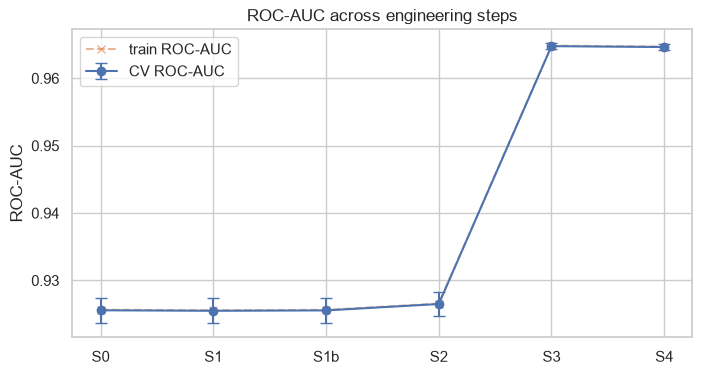

In [25]:
log_df = pd.DataFrame(cv_log)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(log_df["step"], log_df["roc_auc_mean"], yerr=log_df["roc_auc_std"],
            marker="o", capsize=4, label="CV ROC-AUC")
ax.plot(log_df["step"], log_df["train_roc_auc"], "x--", alpha=0.6, label="train ROC-AUC")
ax.set(title="ROC-AUC across engineering steps", ylabel="ROC-AUC")
ax.legend()
plt.show()

## 6. Feature selection: SelectKBest (mutual information) vs RFECV

After S4 we have 26 columns. We want ≤ 20, for two reasons: the rubric's PCA threshold, and because we want SHAP plots in Week 3–4 to show a readable number of named features. The two methods are quite different:

- **A: `SelectKBest(mutual_info_classif)`** is a filter. It looks at each feature on its own and doesn't care about the model. MI is estimated on a 20k-row subsample of each training fold (kNN-based MI on 83k rows is slow), and the discrete columns are marked as discrete.
- **B: `RFECV` with logistic regression** is a wrapper. It repeatedly drops the feature with the smallest |coefficient| and uses an inner 5-fold CV to choose the size. We wrapped it as `CappedRFECV` (in `src/airline_fe/selection.py`): if RFECV's best size is above 20, it takes the best size ≤ 20 from the same CV curve.

Both selectors sit inside the pipeline after `preprocess`, so every outer fold selects features using only its own training part.

In [26]:
# fit the S4 preprocessing once (inside a Pipeline) just to get the column names / types
prep_s4 = Pipeline([("preprocess", build_preprocessor(**STEPS["S4"]))]).fit(X_train, y_train)
feature_names = prep_s4.get_feature_names_out()
continuous = {"Age", "Flight Distance", "Departure Delay", "Net Delay Recovery"}
discrete_mask = np.array([name not in continuous for name in feature_names])
print(len(feature_names), "features,", discrete_mask.sum(), "discrete")

26 features, 22 discrete


### Method A: SelectKBest with mutual information

We try k = 8, 10, …, 20 and use the one-standard-error rule: take the smallest k whose mean ROC-AUC is within one std of the best k. (k is picked on the same outer folds we report, so the winning score is a tiny bit optimistic. With differences this small it doesn't change the conclusion.)

best mean at k = 20 -> one-std rule picks k = 20


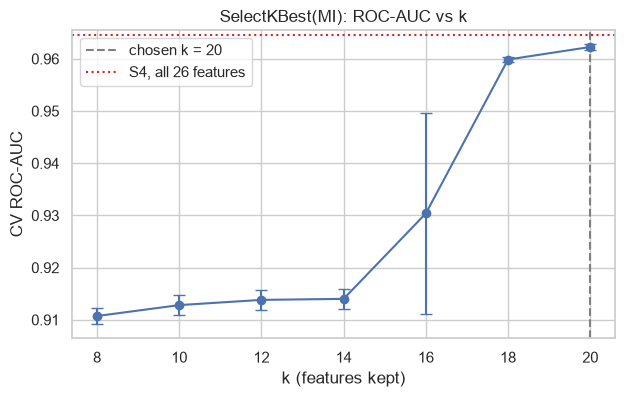

In [27]:
mi_score = partial(mi_subsampled, discrete_mask=discrete_mask, n=20_000, random_state=RANDOM_STATE)
K_GRID = [8, 10, 12, 14, 16, 18, 20]

kbest_results = {}
for k in K_GRID:
    kbest_results[k] = cross_validate(make_pipe(SelectKBest(mi_score, k=k)), X_train, y_train,
                                      cv=CV, scoring=SCORING, n_jobs=-1,
                                      return_train_score=True, return_estimator=True)

k_curve = pd.DataFrame({k: {"mean": r["test_roc_auc"].mean(), "std": r["test_roc_auc"].std(ddof=1)}
                        for k, r in kbest_results.items()}).T
best = k_curve["mean"].idxmax()
best_k = k_curve.index[k_curve["mean"] >= k_curve.loc[best, "mean"] - k_curve.loc[best, "std"]].min()
print("best mean at k =", best, "-> one-std rule picks k =", best_k)

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(k_curve.index, k_curve["mean"], yerr=k_curve["std"], marker="o", capsize=4)
ax.axvline(best_k, ls="--", color="grey", label=f"chosen k = {best_k}")
ax.axhline(cv_log[-1]["roc_auc_mean"], ls=":", color="tab:red", label="S4, all 26 features")
ax.set(xlabel="k (features kept)", ylabel="CV ROC-AUC", title="SelectKBest(MI): ROC-AUC vs k")
ax.legend()
plt.show()

In [28]:
res_a = log_step("S5a", f"SelectKBest(MI), k={best_k}", result=kbest_results[best_k], ref="S4")

,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc,fit_time_s,ref,delta_roc_auc,paired_std,verdict
step,,,,,,,,,,,,,
S0,22,0.92557,0.00187,0.92997,0.00177,0.85130,0.00315,0.92564,0.57805,NaN,NaN,NaN,NaN
S1,22,0.92550,0.00189,0.92991,0.00177,0.85128,0.00304,0.92557,0.55364,S0,-0.00007,0.00004,worsened
S1b,22,0.92555,0.00187,0.92996,0.00177,0.85130,0.00324,0.92563,0.51626,S1,0.00005,0.00004,improved
S2,22,0.92650,0.00181,0.93052,0.00171,0.85161,0.00344,0.92657,0.64509,S1,0.00100,0.00019,improved
S3,36,0.96477,0.00040,0.95764,0.00052,0.88753,0.00180,0.96484,1.18756,S2,0.03827,0.00149,improved
S4,26,0.96463,0.00040,0.95716,0.00042,0.88762,0.00185,0.96470,0.88149,S3,-0.00013,0.00002,worsened
S5a,20,0.96227,0.00052,0.95525,0.00039,0.88451,0.00250,0.96221,0.79684,S4,-0.00237,0.00038,worsened


### Method B: RFECV (capped at 20)

In [29]:
rfe_selector = CappedRFECV(
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    max_features=20, step=1, min_features_to_select=5,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="roc_auc", n_jobs=1,
)
res_b = log_step("S5b", "CappedRFECV(LR), max 20", make_pipe(rfe_selector), ref="S4")

,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc,fit_time_s,ref,delta_roc_auc,paired_std,verdict
step,,,,,,,,,,,,,
S0,22,0.92557,0.00187,0.92997,0.00177,0.85130,0.00315,0.92564,0.57805,NaN,NaN,NaN,NaN
S1,22,0.92550,0.00189,0.92991,0.00177,0.85128,0.00304,0.92557,0.55364,S0,-0.00007,0.00004,worsened
S1b,22,0.92555,0.00187,0.92996,0.00177,0.85130,0.00324,0.92563,0.51626,S1,0.00005,0.00004,improved
S2,22,0.92650,0.00181,0.93052,0.00171,0.85161,0.00344,0.92657,0.64509,S1,0.00100,0.00019,improved
S3,36,0.96477,0.00040,0.95764,0.00052,0.88753,0.00180,0.96484,1.18756,S2,0.03827,0.00149,improved
S4,26,0.96463,0.00040,0.95716,0.00042,0.88762,0.00185,0.96470,0.88149,S3,-0.00013,0.00002,worsened
S5a,20,0.96227,0.00052,0.95525,0.00039,0.88451,0.00250,0.96221,0.79684,S4,-0.00237,0.00038,worsened
S5b,20,0.96445,0.00043,0.95693,0.00036,0.88687,0.00223,0.96450,23.95719,S4,-0.00019,0.00008,worsened


To get one feature list per method (and the RFECV curve), we fit each selector once on the whole training set:

plain RFECV would keep 26 features; capped -> 20


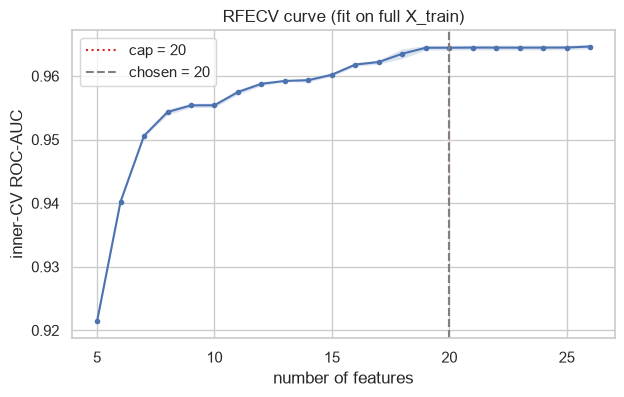

In [30]:
full_a = make_pipe(SelectKBest(mi_score, k=best_k)).fit(X_train, y_train)
full_b = make_pipe(clone(rfe_selector)).fit(X_train, y_train)

rfe_fitted = full_b.named_steps["select"]
curve = pd.DataFrame({k: rfe_fitted.cv_results_[k] for k in ["n_features", "mean_test_score", "std_test_score"]})
print("plain RFECV would keep", rfe_fitted.uncapped_n_features_, "features; capped ->", rfe_fitted.n_features_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve["n_features"], curve["mean_test_score"], marker=".")
ax.fill_between(curve["n_features"], curve["mean_test_score"] - curve["std_test_score"],
                curve["mean_test_score"] + curve["std_test_score"], alpha=0.2)
ax.axvline(20, ls=":", color="tab:red", label="cap = 20")
ax.axvline(rfe_fitted.n_features_, ls="--", color="grey", label=f"chosen = {rfe_fitted.n_features_}")
ax.set(xlabel="number of features", ylabel="inner-CV ROC-AUC", title="RFECV curve (fit on full X_train)")
ax.legend()
plt.show()

### Side-by-side comparison

In [31]:
sel_a = set(full_a[:-1].get_feature_names_out())
sel_b = set(full_b[:-1].get_feature_names_out())
all_feats = list(feature_names)
jaccard = len(sel_a & sel_b) / len(sel_a | sel_b)

def summary(name, selected, result):
    return {
        "method": name,
        "n_selected": len(selected),
        "ROC-AUC": f"{result['test_roc_auc'].mean():.4f} ± {result['test_roc_auc'].std(ddof=1):.4f}",
        "PR-AUC": f"{result['test_pr_auc'].mean():.4f} ± {result['test_pr_auc'].std(ddof=1):.4f}",
        "F1": f"{result['test_f1'].mean():.4f} ± {result['test_f1'].std(ddof=1):.4f}",
        "fit_time_s": round(result["fit_time"].mean(), 1),
        "removed": ", ".join(f for f in all_feats if f not in selected),
    }

comparison = pd.DataFrame([
    summary("S4: no selection", set(all_feats), res_s4),
    summary(f"A: SelectKBest(MI), k={best_k}", sel_a, res_a),
    summary("B: CappedRFECV(LR)", sel_b, res_b),
]).set_index("method")
print(f"Jaccard overlap of A and B: {jaccard:.2f}")
print("in A only:", sorted(sel_a - sel_b))
print("in B only:", sorted(sel_b - sel_a))
with pd.option_context("display.max_colwidth", None):
    display(comparison)

Jaccard overlap of A and B: 0.67
in A only: ['Age', 'Flight Distance', 'Food and Drink', 'Seat Comfort']
in B only: ['Departure and Arrival Time Convenience', 'Departure and Arrival Time Convenience_is_na', 'Ease of Online Booking_is_na', 'Online Boarding_is_na']


,n_selected,ROC-AUC,PR-AUC,F1,fit_time_s,removed
method,,,,,,
S4: no selection,26,0.9646 ± 0.0004,0.9572 ± 0.0004,0.8876 ± 0.0019,0.9,
"A: SelectKBest(MI), k=20",20,0.9623 ± 0.0005,0.9553 ± 0.0004,0.8845 ± 0.0025,0.8,"Gender_Male, Net Delay Recovery, Departure and Arrival Time Convenience, Departure and Arrival Time Convenience_is_na, Ease of Online Booking_is_na, Online Boarding_is_na"
B: CappedRFECV(LR),20,0.9644 ± 0.0004,0.9569 ± 0.0004,0.8869 ± 0.0022,24.0,"Gender_Male, Age, Flight Distance, Net Delay Recovery, Seat Comfort, Food and Drink"


How stable is each method? For every outer fold we check which features it kept (5 = picked in all folds):

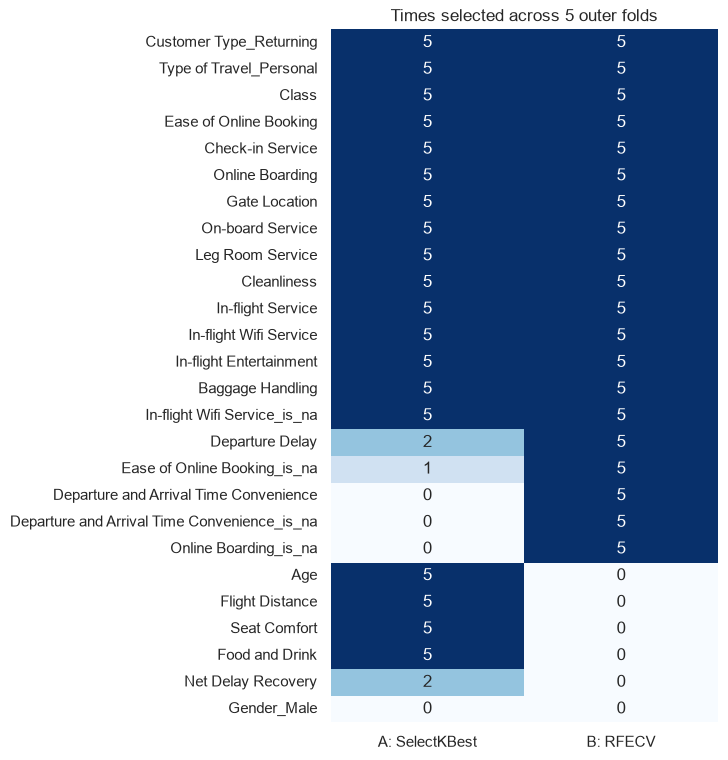

In [32]:
stability = pd.DataFrame({
    "A: SelectKBest": np.sum([e[-2].get_support() for e in res_a["estimator"]], axis=0),
    "B: RFECV": np.sum([e[-2].get_support() for e in res_b["estimator"]], axis=0),
}, index=feature_names)

fig, ax = plt.subplots(figsize=(5, 9))
sns.heatmap(stability.sort_values(["B: RFECV", "A: SelectKBest"], ascending=False),
            annot=True, cmap="Blues", vmin=0, vmax=5, cbar=False, ax=ax)
ax.set_title("Times selected across 5 outer folds")
plt.show()

In [33]:
d = fold_auc["S5a"] - fold_auc["S5b"]
print(f"A - B ROC-AUC: {d.mean():+.5f} (paired std {d.std(ddof=1):.5f})")

if abs(d.mean()) > d.std(ddof=1):
    winner = "A" if d.mean() > 0 else "B"
    rule = "clearly higher CV ROC-AUC"
elif len(sel_a) != len(sel_b):
    winner = "A" if len(sel_a) < len(sel_b) else "B"
    rule = "tie on ROC-AUC -> fewer features"
else:
    winner = "B"
    rule = "tie on ROC-AUC and size -> RFECV (model-aware, same model family as our Week 3 baseline)"

FINAL_SELECTOR = clone(full_a[-2]) if winner == "A" else clone(rfe_selector)
final_fit = full_a if winner == "A" else full_b
final_features = list(final_fit[:-1].get_feature_names_out())
print("winner:", winner, "|", rule)
assert len(final_features) <= 20

A - B ROC-AUC: -0.00218 (paired std 0.00037)
winner: B | clearly higher CV ROC-AUC


**What each method did**

- **SelectKBest(MI)**: the score keeps rising up to k = 20, so the one-std rule picks k = 20. The jump between k = 14 and k = 18 (with the huge error bar at k = 16) comes from Departure Delay and the Wifi flag being picked in some folds and not in others. CV ROC-AUC is 0.9623, which is 0.0024 *below* S4. MI kept Age, Flight Distance, Seat Comfort and Food & Drink. It dropped three of the four flags, Time Convenience, Net Delay Recovery and Gender.
- **CappedRFECV**: plain RFECV wanted all 26 features, but its curve is flat from about 19 upward, so the cap at 20 costs almost nothing. CV ROC-AUC is 0.9644, only 0.0002 below S4. It removed Gender, Age, Flight Distance, Net Delay Recovery, Seat Comfort and Food & Drink, and it picked exactly the same 20 features in all five folds.

**Why they disagree** (Jaccard 0.67). MI scores every feature on its own. Seat Comfort and Food & Drink look useful in isolation, but most of what they say is already in Cleanliness and Entertainment (ρ 0.66–0.69). RFE sees the features together and drops them. With the flags it's the other way round. Alone they have little MI, because only 2–5% of rows are 1. Combined with the rating, they fix the "0 is not a low score" problem, so RFE keeps all four.

**Decision.** RFECV wins by our first rule: it's 0.0022 ROC-AUC ahead, about 6× the paired std. It's also perfectly stable across folds. The downside is fit time (~21 s vs ~1 s per fold), but that's training only; predicting with 20 features costs the same either way. Both methods drop Net Delay Recovery and Gender. Our engineered delay feature turning out useless once Departure Delay is in was a bit disappointing, but its job in S1 was removing the collinearity, and it did that. For SQ1, the interesting features are the ones the two methods disagree on.

## 7. Dimensionality reduction

After selection we have ≤ 20 features, so by the project rules PCA isn't required. We also deliberately keep it out of the predictive pipeline. In Week 3–4 we want to explain the model with SHAP (sub-question 2: *which* touchpoints drive satisfaction for business vs personal travellers). Principal components are mixtures of all features, and "PC3 increases satisfaction" doesn't answer that question.

For completeness we still look at the explained variance of the selected features, and at what PCA(90%) would do to the CV score. The fitted `preprocess → select` part from above is reused as a frozen step, so nothing is refit and everything is still fit only on `X_train`.

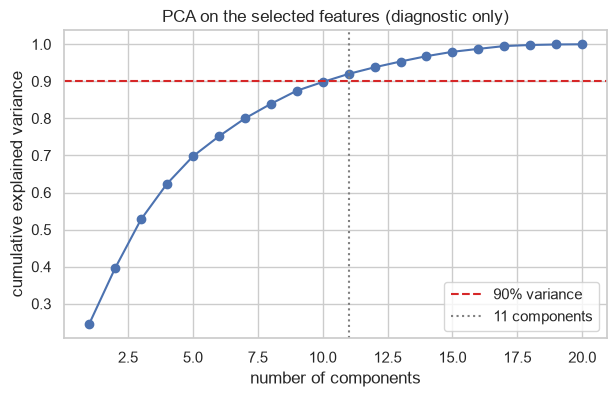

11 of 20 components needed for 90% of the variance


In [34]:
pca_diag = Pipeline([
    ("prep", FrozenEstimator(final_fit[:-1])),   # already fit on X_train
    ("pca", PCA(random_state=RANDOM_STATE)),
]).fit(X_train)

cum = np.cumsum(pca_diag.named_steps["pca"].explained_variance_ratio_)
n_90 = int(np.argmax(cum >= 0.90) + 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(cum) + 1), cum, marker="o")
ax.axhline(0.90, ls="--", color="tab:red", label="90% variance")
ax.axvline(n_90, ls=":", color="grey", label=f"{n_90} components")
ax.set(xlabel="number of components", ylabel="cumulative explained variance",
       title="PCA on the selected features (diagnostic only)")
ax.legend()
plt.show()
print(f"{n_90} of {len(cum)} components needed for 90% of the variance")

In [35]:
pca_pipe = Pipeline([
    ("preprocess", build_preprocessor()),
    ("select", clone(FINAL_SELECTOR)),
    ("pca", PCA(n_components=0.90, random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
res_pca = log_step("S6 (not used)", "selected features -> PCA(0.90)", pca_pipe, ref="S5a" if winner == "A" else "S5b")

,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc,fit_time_s,ref,delta_roc_auc,paired_std,verdict
step,,,,,,,,,,,,,
S0,22,0.92557,0.00187,0.92997,0.00177,0.85130,0.00315,0.92564,0.57805,NaN,NaN,NaN,NaN
S1,22,0.92550,0.00189,0.92991,0.00177,0.85128,0.00304,0.92557,0.55364,S0,-0.00007,0.00004,worsened
S1b,22,0.92555,0.00187,0.92996,0.00177,0.85130,0.00324,0.92563,0.51626,S1,0.00005,0.00004,improved
S2,22,0.92650,0.00181,0.93052,0.00171,0.85161,0.00344,0.92657,0.64509,S1,0.00100,0.00019,improved
S3,36,0.96477,0.00040,0.95764,0.00052,0.88753,0.00180,0.96484,1.18756,S2,0.03827,0.00149,improved
S4,26,0.96463,0.00040,0.95716,0.00042,0.88762,0.00185,0.96470,0.88149,S3,-0.00013,0.00002,worsened
S5a,20,0.96227,0.00052,0.95525,0.00039,0.88451,0.00250,0.96221,0.79684,S4,-0.00237,0.00038,worsened
S5b,20,0.96445,0.00043,0.95693,0.00036,0.88687,0.00223,0.96450,23.95719,S4,-0.00019,0.00008,worsened
S6 (not used),11,0.90603,0.00267,0.90726,0.00268,0.81615,0.00475,0.90609,37.65365,S5b,-0.05842,0.00231,worsened


Even as a diagnostic, PCA backs up the decision. Reaching 90% of the variance of the 20 selected features takes 11 components, and LR on those 11 components drops to ROC-AUC **0.906**, which is 0.058 below the selected features. PCA keeps the directions with the most variance. Our 0/1 flags have tiny variance but, as S3 showed, a lot of signal, so they are probably the first thing to get lost. PCA would cost us both accuracy and interpretability, so it stays out of the pipeline.

### 2D view with t-SNE

The transformation is fit on all of `X_train` (same frozen `preprocess → select` as above). t-SNE itself runs on a stratified 5,000-row subsample of the training set, since it scales badly. Left: coloured by satisfaction. Right: by type of travel, as a preview of SQ2.

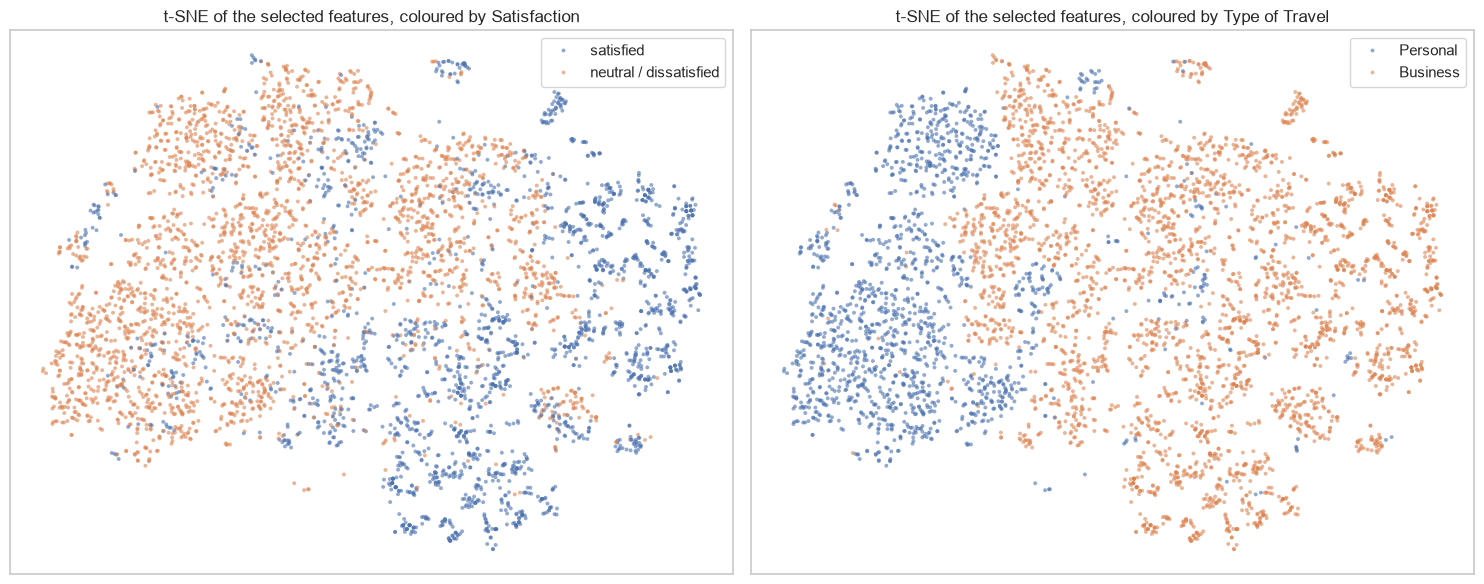

In [36]:
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=5000,
                                      stratify=y_train, random_state=RANDOM_STATE)

tsne = Pipeline([
    ("prep", FrozenEstimator(final_fit[:-1])),
    ("tsne", TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE)),
])
Z = tsne.fit_transform(X_sub)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, labels, title in [
    (axes[0], y_sub.map({0: "neutral / dissatisfied", 1: "satisfied"}), "coloured by Satisfaction"),
    (axes[1], X_sub["Type of Travel"], "coloured by Type of Travel"),
]:
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=labels.values, s=8, alpha=0.6, linewidth=0, ax=ax)
    ax.set(title=f"t-SNE of the selected features, {title}", xticks=[], yticks=[])
plt.tight_layout()
plt.savefig(REPORTS / "tsne.png", dpi=90)
plt.show()

The two classes are far from randomly mixed. Satisfied passengers mostly sit in the lower-right part of the map, and dissatisfied ones fill the left and the top. There's no clean boundary, though: the middle band overlaps a lot, and there are small satisfied islands inside the dissatisfied area and the other way round. The right panel shows where much of the structure comes from. Personal travellers form their own region on the left, and it is almost all "neutral / dissatisfied", matching the 10% satisfaction rate for personal trips. Business travellers spread over the rest of the map and split into satisfied and dissatisfied sub-clusters, so for them the service ratings are what decides the outcome. That's a good sign for SQ2: the two groups really seem to be driven by different things.

For Week 3 this fits the CV results. The broad separation is why a linear model already reaches ~0.964 ROC-AUC. The mixed islands (together with the side experiment) are the part where a non-linear model should be able to gain. One caveat: t-SNE only preserves local neighbourhoods, so we don't read anything into the distances between far-apart clusters.

## 8. Final feature set and CV log

In [37]:
print(f"{len(final_features)} features go into the model:")
for name in final_features:
    print("  -", name)

log_out = pd.DataFrame(cv_log)
log_out.to_csv(REPORTS / "week2_cv_log.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(log_out[["step", "description", "n_features", "roc_auc_mean", "roc_auc_std",
                     "pr_auc_mean", "f1_mean", "delta_roc_auc", "paired_std", "verdict"]].round(4))

20 features go into the model:
  - Customer Type_Returning
  - Type of Travel_Personal
  - Class
  - Departure Delay
  - Departure and Arrival Time Convenience
  - Ease of Online Booking
  - Check-in Service
  - Online Boarding
  - Gate Location
  - On-board Service
  - Leg Room Service
  - Cleanliness
  - In-flight Service
  - In-flight Wifi Service
  - In-flight Entertainment
  - Baggage Handling
  - Departure and Arrival Time Convenience_is_na
  - Ease of Online Booking_is_na
  - Online Boarding_is_na
  - In-flight Wifi Service_is_na


,step,description,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,f1_mean,delta_roc_auc,paired_std,verdict
0,S0,"raw features, impute + RobustScaler + encoders",22,0.9256,0.0019,0.9300,0.8513,NaN,NaN,NaN
1,S1,"Departure - Arrival -> Net Delay Recovery, drop Arrival",22,0.9255,0.0019,0.9299,0.8513,-0.0001,0.0000,worsened
2,S1b,S1 but impute Arrival with its own median,22,0.9255,0.0019,0.9300,0.8513,0.0001,0.0000,improved
3,S2,log1p on Flight Distance and Departure Delay,22,0.9265,0.0018,0.9305,0.8516,0.0010,0.0002,improved
4,S3,add all 14 <rating>_is_na flags,36,0.9648,0.0004,0.9576,0.8875,0.0383,0.0015,improved
5,S4,VarianceThreshold(0.0099) on the flags,26,0.9646,0.0004,0.9572,0.8876,-0.0001,0.0000,worsened
6,S5a,"SelectKBest(MI), k=20",20,0.9623,0.0005,0.9553,0.8845,-0.0024,0.0004,worsened
7,S5b,"CappedRFECV(LR), max 20",20,0.9644,0.0004,0.9569,0.8869,-0.0002,0.0001,worsened
8,S6 (not used),selected features -> PCA(0.90),11,0.9060,0.0027,0.9073,0.8162,-0.0584,0.0023,worsened


To sum up the engineering: the step that really mattered was S3 (zero-flags, +0.038 ROC-AUC), followed far behind by S2 (log1p, +0.001). S1 left the score unchanged but fixed the delay coefficients. S4 plus feature selection removed 16 of the 36 candidate columns, and the total cost was about 0.0003 ROC-AUC (0.9648 → 0.9645). The full log is saved to `reports/week2_cv_log.csv`.

## 9. Final pipeline

Build the full pipeline from scratch, fit it on `X_train`, and use it on `X_test` for the first time. The test score is printed only as a sanity check; no decision above was made with it.

In [38]:
final_pipe = make_pipe(clone(FINAL_SELECTOR))
final_pipe.fit(X_train, y_train)

Xt_train = final_pipe[:-1].transform(X_train)
Xt_test = final_pipe[:-1].transform(X_test)
y_pred = final_pipe.predict(X_test)

print("raw shapes:         ", X_train.shape, X_test.shape)
print("transformed shapes: ", Xt_train.shape, Xt_test.shape)
print("y_pred shape:       ", y_pred.shape)
assert Xt_train.shape[1] == Xt_test.shape[1] <= 20
print("selected features:  ", list(final_pipe[:-1].get_feature_names_out()))
print(f"test ROC-AUC (sanity check only): {roc_auc_score(y_test, final_pipe.predict_proba(X_test)[:, 1]):.4f}")

# make sure it survives saving/loading (we'll need that for the Week 4 app)
buffer = io.BytesIO()
joblib.dump(final_pipe, buffer)
buffer.seek(0)
reloaded = joblib.load(buffer)
assert np.allclose(reloaded.predict_proba(X_test), final_pipe.predict_proba(X_test))

final_pipe

raw shapes:          (103904, 22) (25976, 22)
transformed shapes:  (103904, 20) (25976, 20)
y_pred shape:        (25976,)
selected features:   ['Customer Type_Returning', 'Type of Travel_Personal', 'Class', 'Departure Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Leg Room Service', 'Cleanliness', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling', 'Departure and Arrival Time Convenience_is_na', 'Ease of Online Booking_is_na', 'Online Boarding_is_na', 'In-flight Wifi Service_is_na']
test ROC-AUC (sanity check only): 0.9657


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('select', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['Gender','Age','Customer Type',...,'In-flight Wifi Service', 'In-flight Entertainment','Baggage Handling']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('nominal', ...), ('class', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that gen